# 03 · Exploratory Data Analysis
Each section has a plot, followed by the insight it gives for modelling. Figures are also saved to `reports/figures/`.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")          # project modules
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

from io_utils import FIG, load_processed
from config import SITES, RAMP_THRESHOLD

data = {}
for s in ("primary", "site_a"):
    d = load_processed(s)
    loc = d.index.tz_convert(SITES[s]["tz"])
    d["hour"], d["month"], d["doy"] = loc.hour, loc.month, loc.dayofyear
    d["date"] = loc.date
    data[s] = d
FIG.mkdir(parents=True, exist_ok=True)
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, dpi=120)
{k: v.shape for k, v in data.items()}

{'primary': (18746, 22), 'site_a': (13031, 22)}

## 1. Time series overview

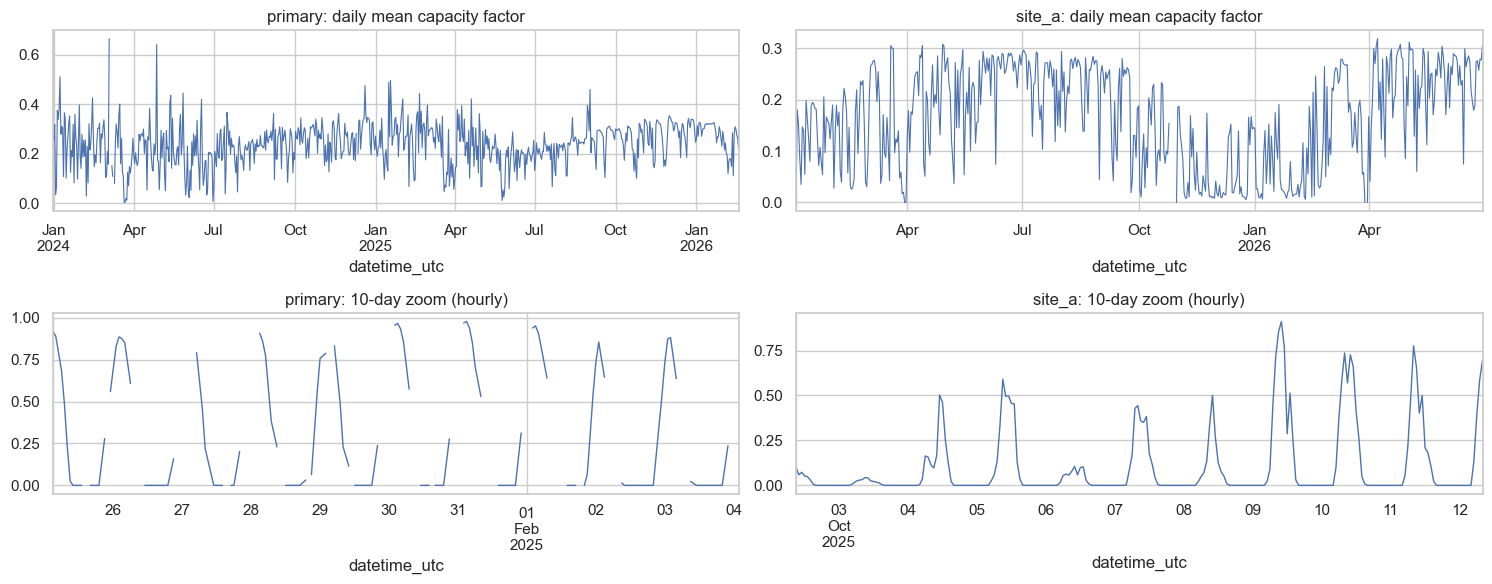

In [2]:
fig, ax = plt.subplots(2, 2, figsize=(15, 6))
for i, (s, d) in enumerate(data.items()):
    d["capacity_factor"].resample("D").mean().plot(ax=ax[0, i], lw=.8)
    ax[0, i].set_title(f"{s}: daily mean capacity factor")
    d["capacity_factor"].iloc[len(d) // 2: len(d) // 2 + 240].plot(ax=ax[1, i], lw=1)
    ax[1, i].set_title(f"{s}: 10-day zoom (hourly)")
save(fig, "01_timeseries.png"); plt.show()

**Insight:** generation is stable apart from logger gaps and cloudy spells. Primary has a mild seasonal swing (sunny desert), while Site A swings strongly between summer and winter.

## 2. Diurnal × seasonal heatmap

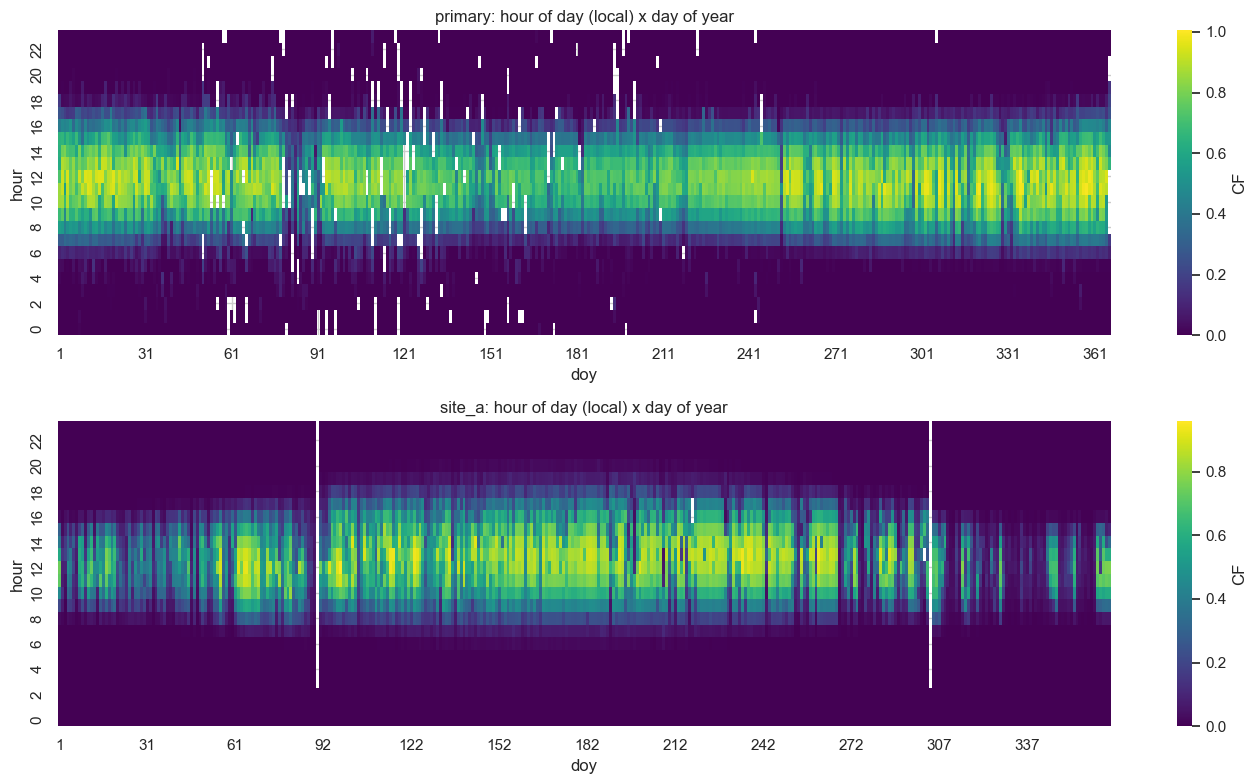

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(14, 8))
for i, (s, d) in enumerate(data.items()):
    piv = d.pivot_table(index="hour", columns="doy", values="capacity_factor")
    sns.heatmap(piv, cmap="viridis", ax=ax[i], xticklabels=30, cbar_kws={"label": "CF"})
    ax[i].invert_yaxis(); ax[i].set_title(f"{s}: hour of day (local) x day of year")
save(fig, "02_diurnal_heatmap.png"); plt.show()

**Insight:** day length changes with the season in the right direction for each hemisphere (longest days in Dec–Jan for primary, in June for Site A), which confirms the timezone handling. Site A's DST changes show up as 1-hour steps around days 90 and 300.

## 3. Distributions by hour and month (daytime only)

primary: best month 10 (0.504), worst month 3 (0.406)
site_a: best month 8 (0.407), worst month 11 (0.153)


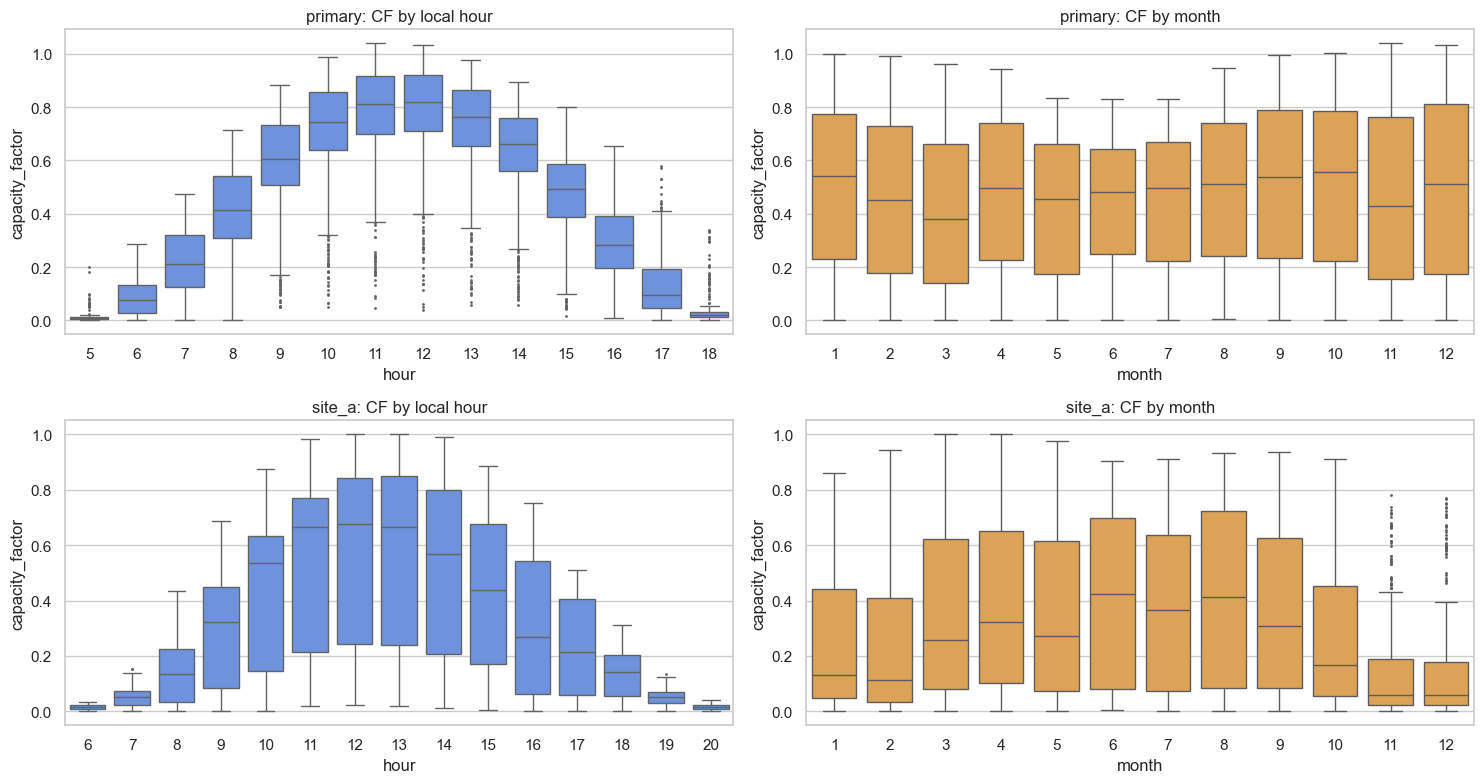

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(15, 8))
for i, (s, d) in enumerate(data.items()):
    day = d[d["is_day"] == 1]
    sns.boxplot(data=day, x="hour", y="capacity_factor", ax=ax[i, 0], fliersize=1, color="#5b8def")
    sns.boxplot(data=day, x="month", y="capacity_factor", ax=ax[i, 1], fliersize=1, color="#f2a541")
    ax[i, 0].set_title(f"{s}: CF by local hour"); ax[i, 1].set_title(f"{s}: CF by month")
    m = day.groupby("month")["capacity_factor"].mean()
    print(f"{s}: best month {m.idxmax()} ({m.max():.3f}), worst month {m.idxmin()} ({m.min():.3f})")
save(fig, "03_boxplots.png"); plt.show()

**Insight:** output peaks at solar noon. The spread is widest in the shoulder hours and in cloudy months, which is where forecast error will concentrate, so errors must be reported **by hour and by season** and not only as one overall number.

## 4. Correlation with weather (daytime)

primary {'ghi': 0.99, 'gti': 0.96, 'solar_elevation': 0.86, 'dhi': 0.53, 'humidity_pct': -0.41, 'temp_c': 0.33, 'clearsky_index': 0.23, 'rain_mm': -0.13, 'wind_dir': 0.01}
site_a {'ghi': 0.9, 'solar_elevation': 0.8, 'dni': 0.79, 'dhi': 0.67, 'humidity_pct': -0.65, 'temp_c': 0.38, 'cloud_cover_pct': -0.34, 'clearsky_index': 0.33, 'wind_speed_kmh': 0.21, 'rain_mm': -0.2}


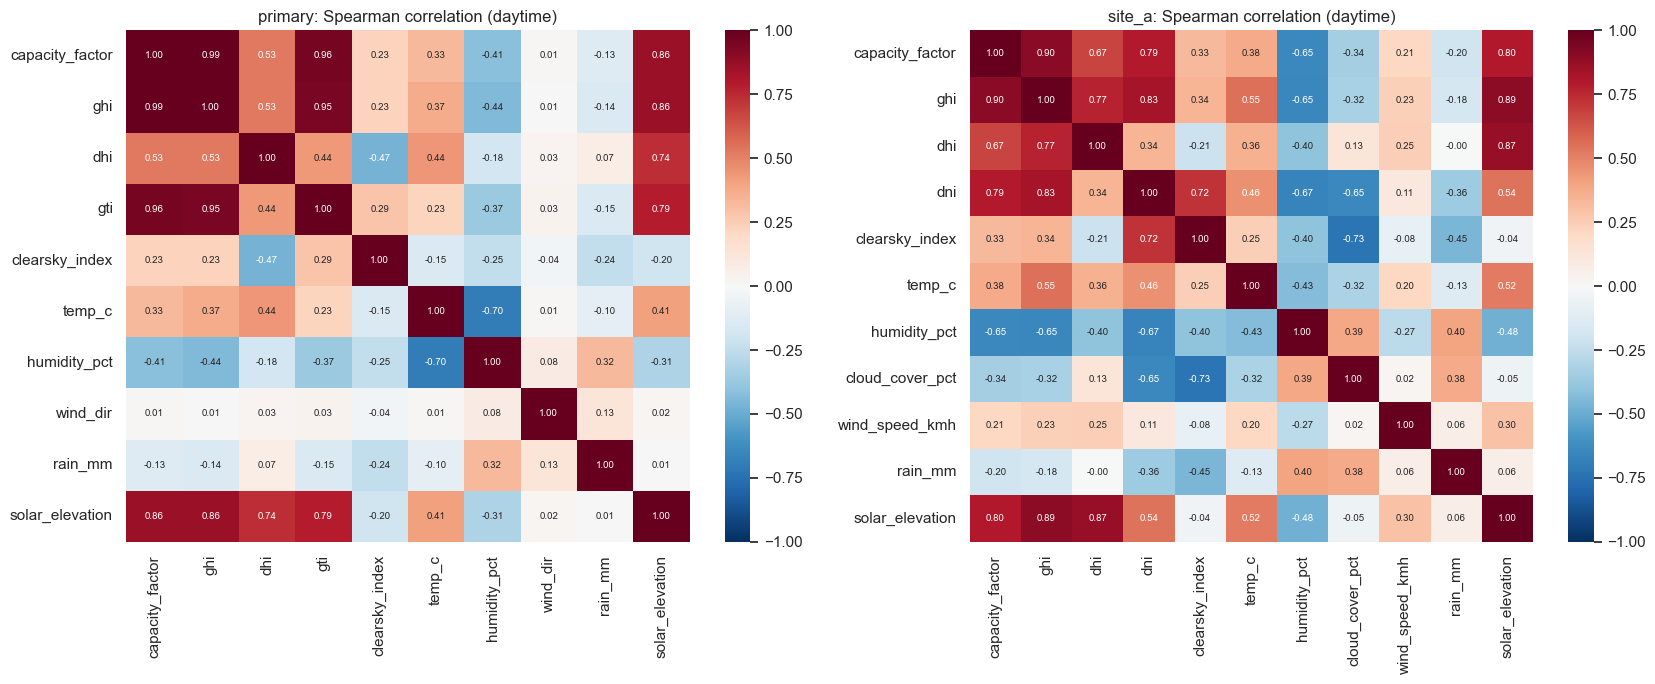

In [5]:
cols = ["capacity_factor", "ghi", "dhi", "dni", "gti", "clearsky_index", "temp_c", "humidity_pct",
        "cloud_cover_pct", "wind_speed_kmh", "wind_dir", "rain_mm", "solar_elevation"]
fig, ax = plt.subplots(1, 2, figsize=(17, 7))
for i, (s, d) in enumerate(data.items()):
    c = [x for x in cols if x in d]
    corr = d.loc[d["is_day"] == 1, c].corr(method="spearman")
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax[i], annot_kws={"size": 7})
    ax[i].set_title(f"{s}: Spearman correlation (daytime)")
    print(s, corr["capacity_factor"].drop("capacity_factor").sort_values(key=abs, ascending=False).round(2).to_dict())
save(fig, "04_correlation.png"); plt.show()

**Insight:** GHI is the main driver (ρ ≈ 0.99 primary, 0.90 Site A). Humidity and cloud cover have a negative effect. At Site A, cloud cover alone (ρ ≈ −0.34) is much weaker than irradiance, so irradiance carries most of the signal.

## 5. CF vs GHI, and the temperature effect

primary: temperature effect = -0.42% per degC
site_a: temperature effect = -0.52% per degC


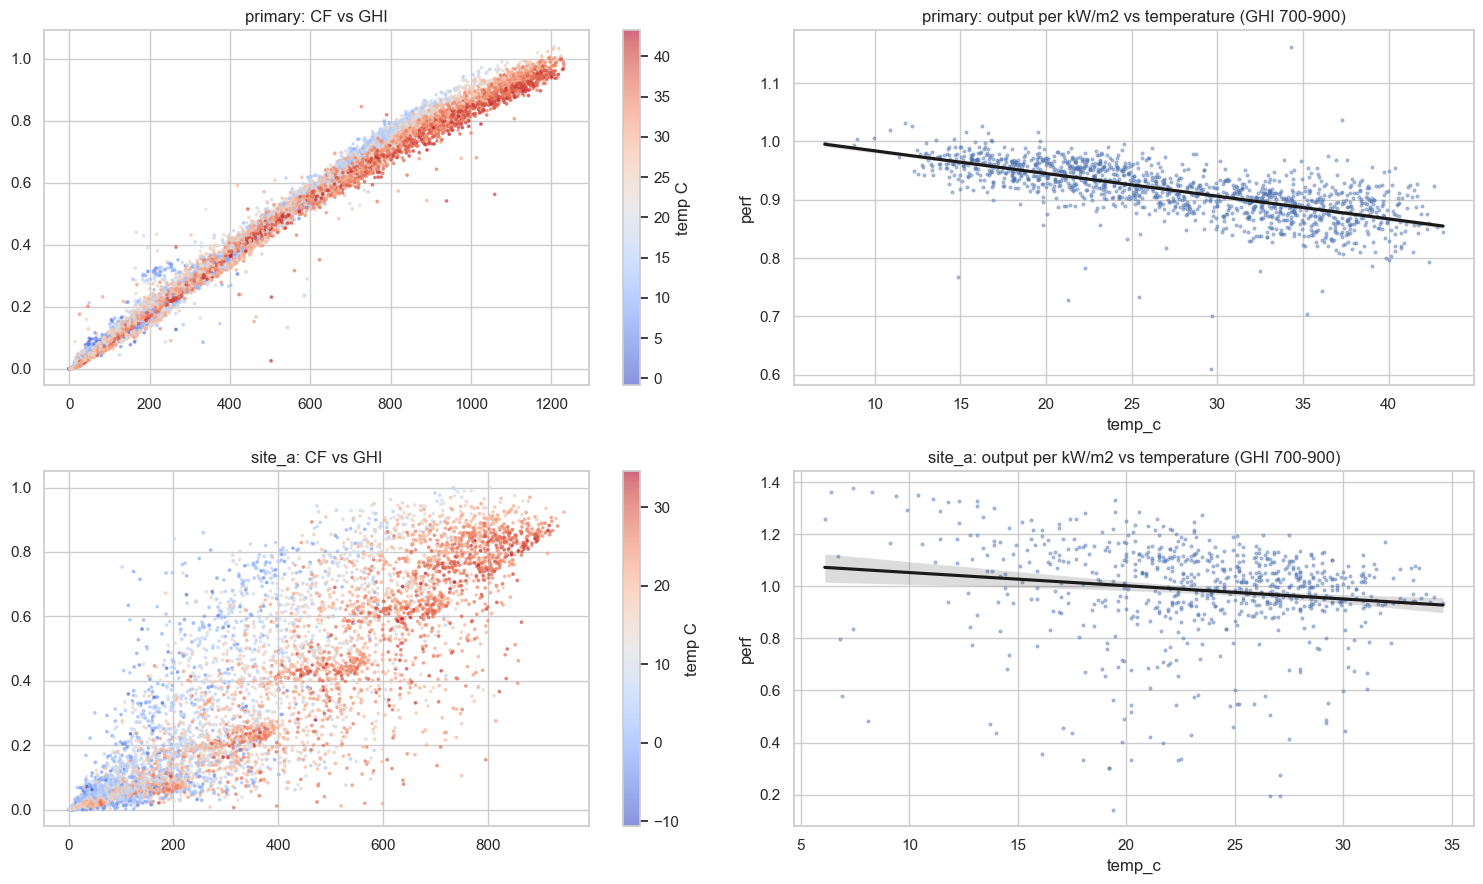

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
for i, (s, d) in enumerate(data.items()):
    day = d[d["is_day"] == 1]
    sc = ax[i, 0].scatter(day["ghi"], day["capacity_factor"], c=day["temp_c"], s=3, cmap="coolwarm", alpha=.6)
    plt.colorbar(sc, ax=ax[i, 0], label="temp C"); ax[i, 0].set_title(f"{s}: CF vs GHI")
    b = day[day["ghi"].between(700, 900)].dropna(subset=["temp_c", "capacity_factor"]).copy()
    b["perf"] = b["capacity_factor"] / b["ghi"] * 1000
    sns.regplot(data=b, x="temp_c", y="perf", ax=ax[i, 1], scatter_kws={"s": 4, "alpha": .4}, line_kws={"color": "k"})
    ax[i, 1].set_title(f"{s}: output per kW/m2 vs temperature (GHI 700-900)")
    slope = np.polyfit(b["temp_c"], b["perf"], 1)[0]
    print(f"{s}: temperature effect = {slope / b['perf'].mean() * 100:+.2f}% per degC")
save(fig, "05_scatter.png"); plt.show()

**Insight:** CF is almost linear in GHI. At high irradiance, output falls by about **0.4–0.5 % per °C**, which matches the crystalline-silicon temperature coefficient (−0.3 to −0.5 %/°C). This justifies the panel-efficiency proxy feature. The flat ceiling at Site A is inverter clipping.

## 6. Seasonal decomposition (STL)

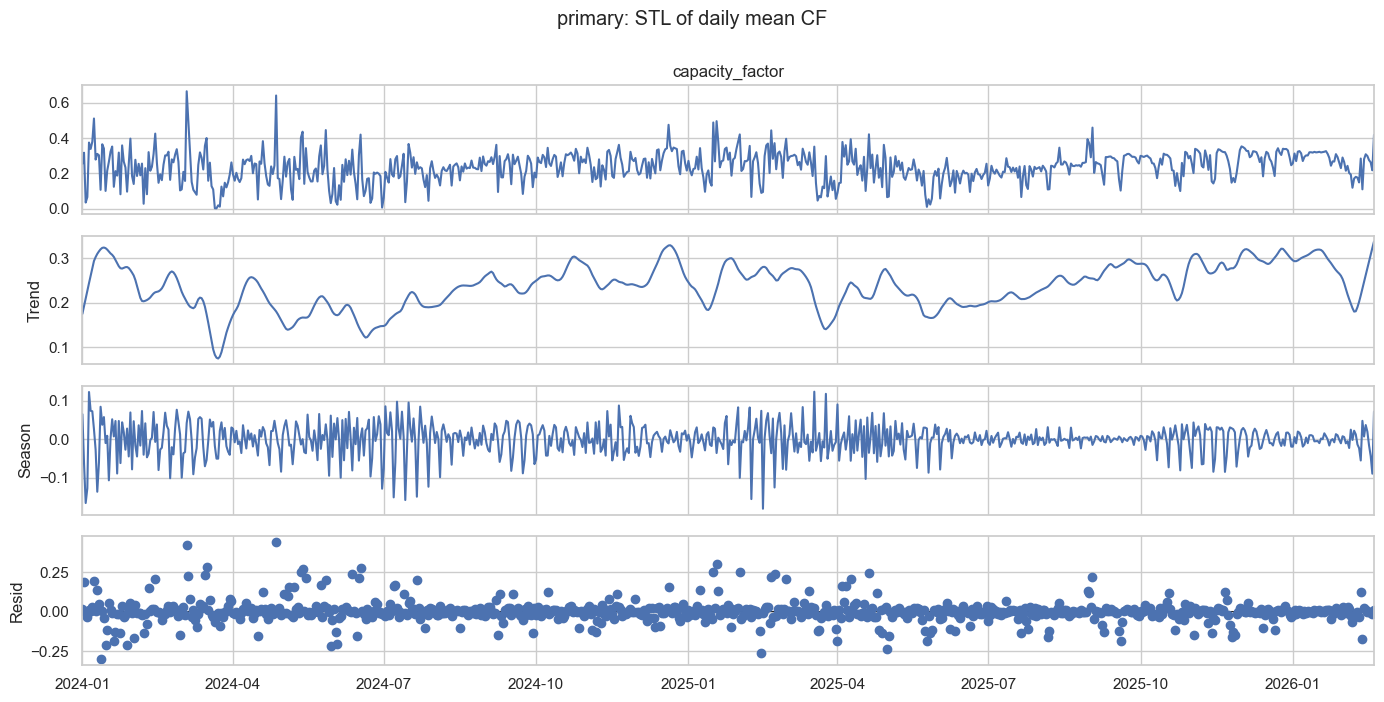

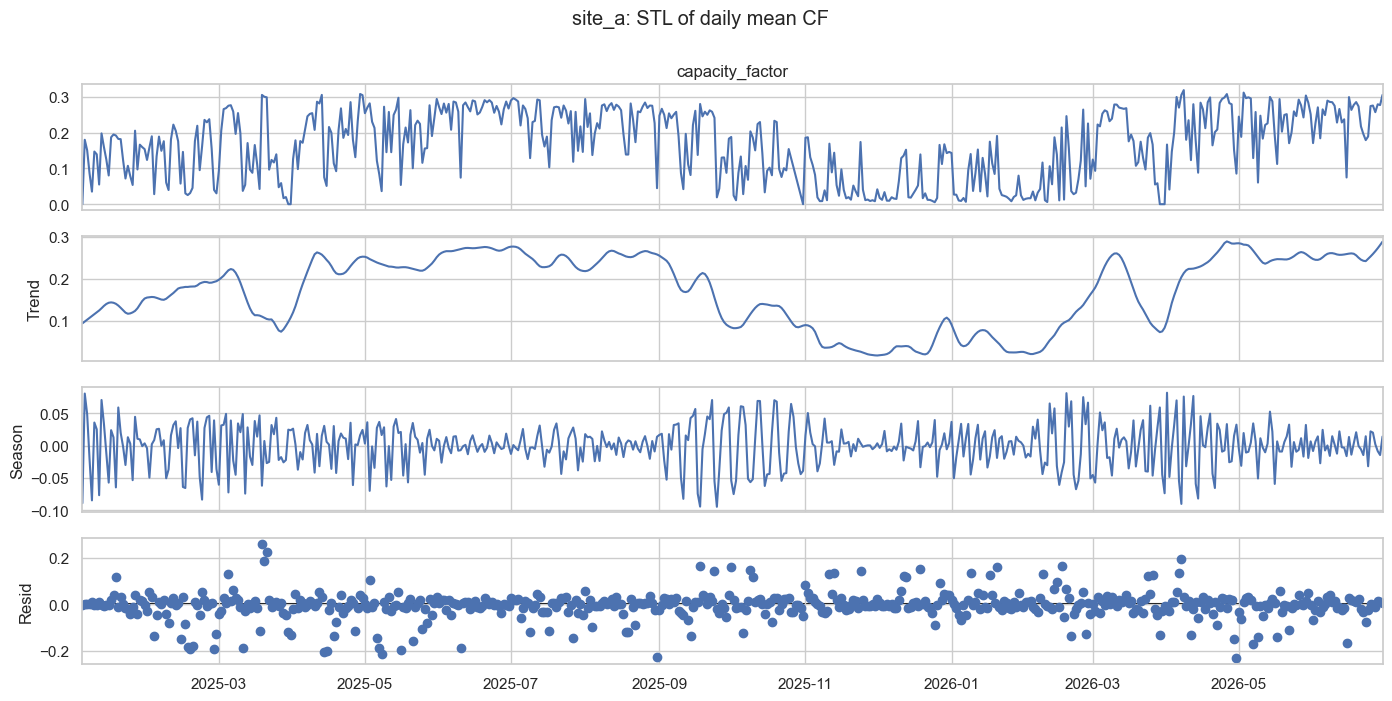

In [7]:
from statsmodels.tsa.seasonal import STL
for s, d in data.items():
    daily = d["capacity_factor"].resample("D").mean().interpolate(limit=7).dropna()
    fig = STL(daily, period=7, robust=True).fit().plot()
    fig.set_size_inches(14, 7); fig.suptitle(f"{s}: STL of daily mean CF", y=1.0)
    save(fig, f"06_stl_{s}.png"); plt.show()

**Insight:** the trend is flat, so there is no visible panel degradation. Variation comes from the seasons and from day-to-day weather (the residual). The residual is what the weather features have to explain.

## 7. Autocorrelation (lag selection)

primary: ACF lag 1 / 24 / 168 = 0.92 / 0.84 / 0.80
site_a: ACF lag 1 / 24 / 168 = 0.92 / 0.83 / 0.73


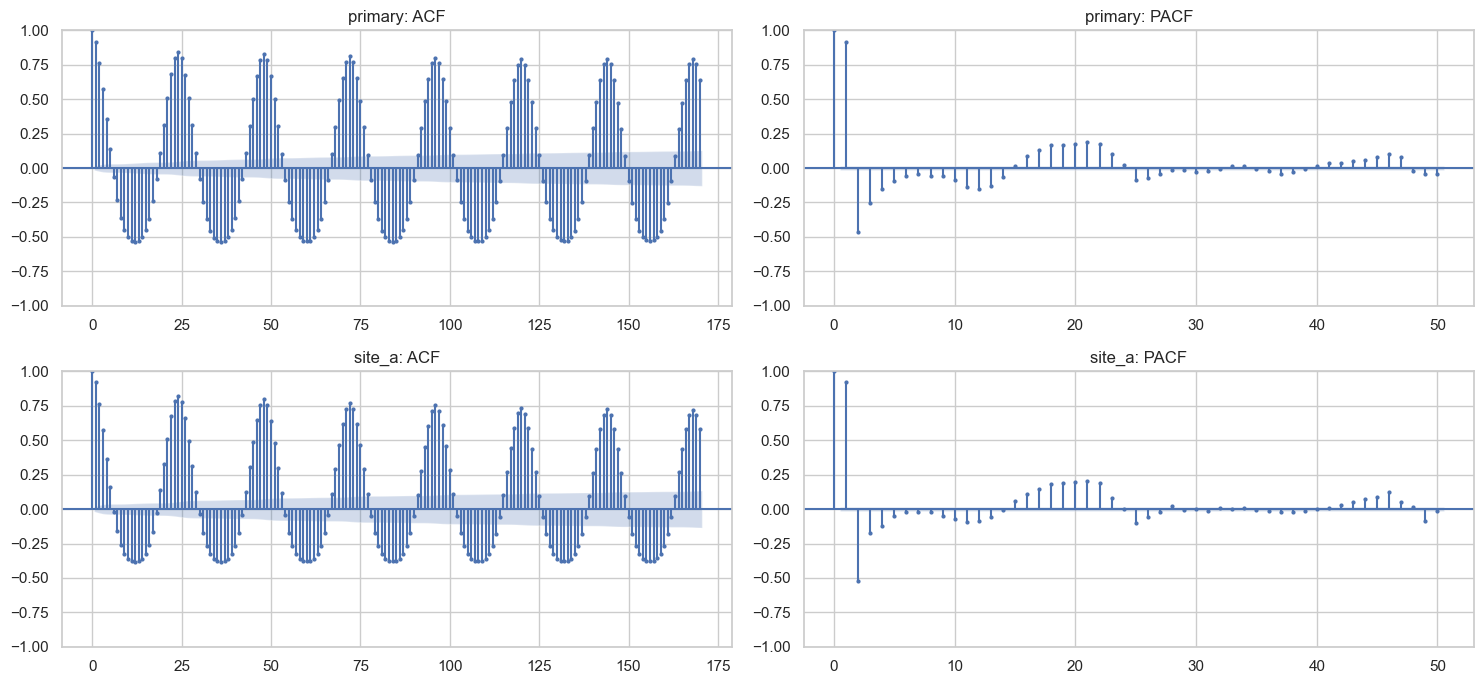

In [8]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
fig, ax = plt.subplots(2, 2, figsize=(15, 7))
for i, (s, d) in enumerate(data.items()):
    x = d["capacity_factor"].interpolate(limit=3).fillna(0)
    plot_acf(x, lags=170, ax=ax[i, 0], markersize=2); ax[i, 0].set_title(f"{s}: ACF")
    plot_pacf(x, lags=50, ax=ax[i, 1], markersize=2, method="ywm"); ax[i, 1].set_title(f"{s}: PACF")
    print(f"{s}: ACF lag 1 / 24 / 168 = {x.autocorr(1):.2f} / {x.autocorr(24):.2f} / {x.autocorr(168):.2f}")
save(fig, "07_acf_pacf.png"); plt.show()

**Insight:** there are strong peaks at lag 24 (same hour yesterday) and lag 168 (same hour last week), and the PACF drops off after a few lags. This supports the lags **t-1, t-2, t-3, t-24 and t-168**. It also warns that persistence and seasonal-naive baselines will be hard to beat.

## 8. Ramp events (sudden drops)
A ramp is a 1-hour drop larger than 20 % of capacity. We separate drops caused by **weather** from those caused by the **sun setting**, since the second kind is predictable from geometry.

primary: threshold 10%: 2141 drops (30.7% of daytime hours)
primary: threshold 20%: 856 drops (12.3% of daytime hours)
primary: threshold 30%: 96 drops (1.4% of daytime hours)
primary: 59 of 856 drops > 20% are weather-driven

site_a: threshold 10%: 1437 drops (24.0% of daytime hours)
site_a: threshold 20%: 630 drops (10.5% of daytime hours)
site_a: threshold 30%: 178 drops (3.0% of daytime hours)
site_a: 174 of 630 drops > 20% are weather-driven



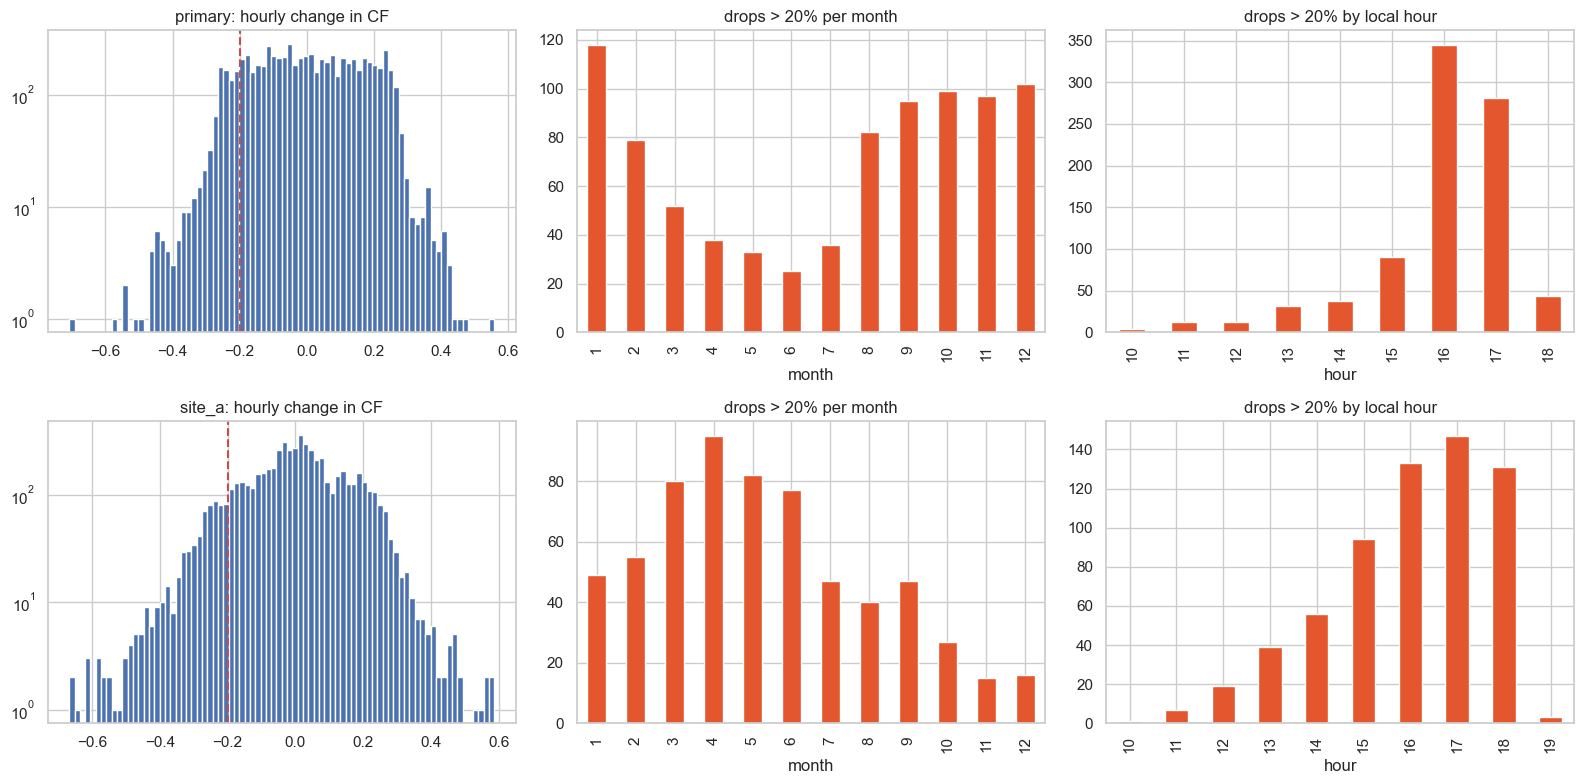

In [9]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for i, (s, d) in enumerate(data.items()):
    dcf = d["capacity_factor"].diff()
    dday = dcf[(d["is_day"] == 1) & (d["is_day"].shift(1) == 1)].dropna()
    drops = dday[dday < -RAMP_THRESHOLD]
    clear_sky_drop = (d["ghi_clearsky"].diff() / d["ghi_clearsky"].max()).loc[drops.index]
    weather = drops[clear_sky_drop > -RAMP_THRESHOLD / 2]

    ax[i, 0].hist(dday, bins=80); ax[i, 0].axvline(-RAMP_THRESHOLD, c="r", ls="--")
    ax[i, 0].set_yscale("log"); ax[i, 0].set_title(f"{s}: hourly change in CF")
    d.loc[drops.index, "month"].value_counts().reindex(range(1, 13), fill_value=0).plot.bar(ax=ax[i, 1], color="#e4572e")
    ax[i, 1].set_title("drops > 20% per month")
    d.loc[drops.index, "hour"].value_counts().sort_index().plot.bar(ax=ax[i, 2], color="#e4572e")
    ax[i, 2].set_title("drops > 20% by local hour")

    for q in (0.10, 0.20, 0.30):
        print(f"{s}: threshold {q:.0%}: {(dday < -q).sum()} drops ({(dday < -q).mean():.1%} of daytime hours)")
    print(f"{s}: {len(weather)} of {len(drops)} drops > 20% are weather-driven\n")
save(fig, "08_ramps.png"); plt.show()

**Insight:** most large drops happen in the afternoon as the sun sets, which is predictable. Only **59 of 856** (primary) but **174 of 630** (Site A) are weather-driven. The ramp alert should therefore target drops **not explained by clear-sky output**, and **Site A is the better testbed** for the alert research question.

## 9. Missing-data calendar

primary: 56 of 781 days have more than half their daytime hours missing
site_a: 11 of 543 days have more than half their daytime hours missing


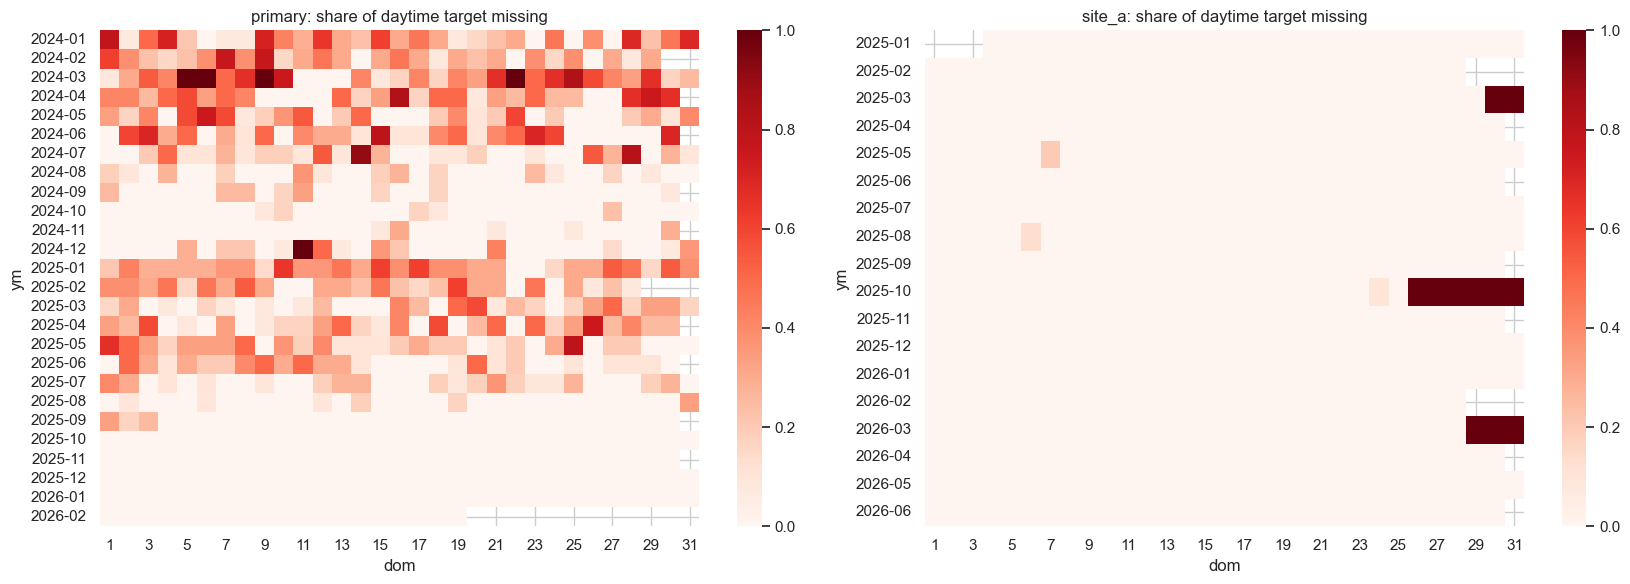

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
for i, (s, d) in enumerate(data.items()):
    day = d[d["is_day"] == 1]
    miss = day["capacity_factor"].isna().groupby(day["date"]).mean()
    miss.index = pd.to_datetime(miss.index)
    m = pd.DataFrame({"v": miss.values, "ym": miss.index.strftime("%Y-%m"), "dom": miss.index.day})
    sns.heatmap(m.pivot(index="ym", columns="dom", values="v"), cmap="Reds", vmin=0, vmax=1, ax=ax[i])
    ax[i].set_title(f"{s}: share of daytime target missing")
    print(f"{s}: {(miss > .5).sum()} of {len(miss)} days have more than half their daytime hours missing")
save(fig, "09_missing.png"); plt.show()

**Insight:** missing data comes in **blocks** (outages lasting days to weeks), not as random single points. This is why long gaps stay NaN rather than being interpolated, and why every evaluation uses only rows where the target exists.

## 10. Sky conditions

primary {'clear': 0.77, 'partly cloudy': 0.15, 'overcast': 0.08}
site_a {'clear': 0.57, 'partly cloudy': 0.28, 'overcast': 0.15}


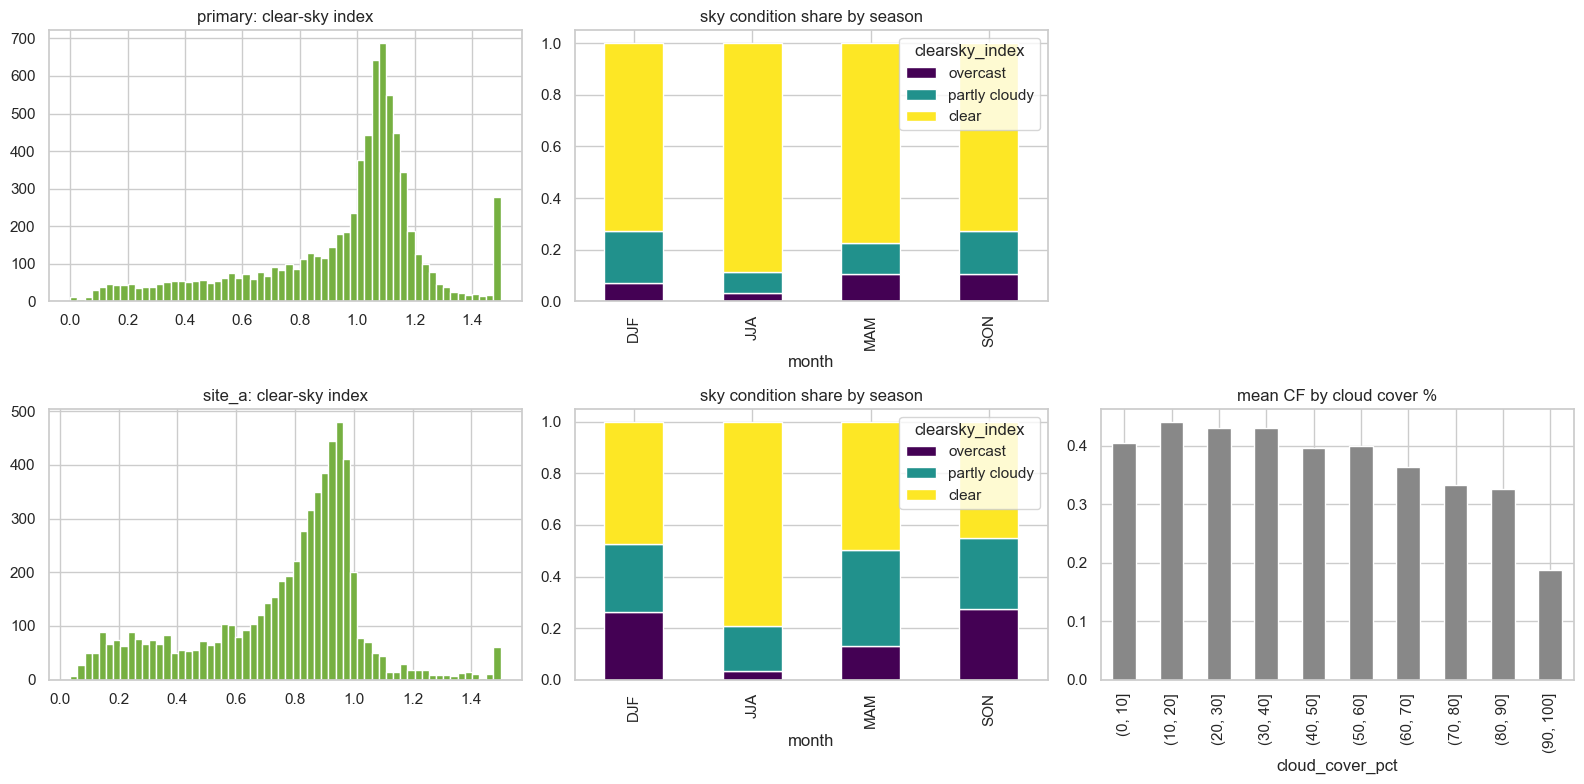

In [11]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for i, (s, d) in enumerate(data.items()):
    day = d[d["is_day"] == 1]
    sky = pd.cut(day["clearsky_index"], [0, .4, .8, 1.6], labels=["overcast", "partly cloudy", "clear"])
    season = day["month"].map({12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
                               6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"})
    ax[i, 0].hist(day["clearsky_index"].dropna(), bins=60, color="#76b041"); ax[i, 0].set_title(f"{s}: clear-sky index")
    pd.crosstab(season, sky, normalize="index").plot.bar(stacked=True, ax=ax[i, 1], colormap="viridis")
    ax[i, 1].set_title("sky condition share by season")
    if "cloud_cover_pct" in day:
        day.groupby(pd.cut(day["cloud_cover_pct"], range(0, 101, 10)), observed=True)["capacity_factor"].mean().plot.bar(ax=ax[i, 2], color="#888")
        ax[i, 2].set_title("mean CF by cloud cover %")
    else:
        ax[i, 2].axis("off")
    print(s, sky.value_counts(normalize=True).round(2).to_dict())
save(fig, "10_sky.png"); plt.show()

**Insight:** the primary site is **77 % clear-sky**, so it is easy to forecast and persistence will be strong. Site A is cloudier (57 % clear, 15 % overcast). Having both climates makes the PRD's 'performance by sky condition' analysis possible.

## Conclusions for modelling
1. **Dataset roles:** primary is the main 26-month benchmark. Site A covers the cloud-cover, ramp-alert and cross-climate questions.
2. Model and score **daytime hours only**, with the target normalised by capacity (CF).
3. Key features: GHI, clear-sky GHI and clear-sky index, solar geometry, lags 1/24/168, rolling statistics, and the temperature efficiency proxy.
4. Baselines will be strong, so every model must report a **skill score against smart persistence**.
5. Ramp alerts should target drops that clear-sky output does not explain.